## Import

In [1]:
import pandas as pd
import numpy as np
import joblib

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

pd.set_option("display.max_columns", None)

## Baca dataset

In [2]:
DATA_PATH = Path("../data/raw/Child Dev.xlsx")

df = pd.read_excel(DATA_PATH)

print("Dataset berhasil dibaca.")
print("Ukuran dataset:", df.shape)

display(df.head())

Dataset berhasil dibaca.
Ukuran dataset: (80000, 8)


,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social,dev_status
0,16,113,1,delayed,advanced,normal,delayed,suspect
1,7,54,3,advanced,normal,caution,caution,suspect
2,17,106,1,delayed,normal,normal,normal,suspect
3,11,114,5,normal,normal,delayed,advanced,suspect
4,20,54,5,caution,advanced,delayed,delayed,suspect


## Validasi struktur data

In [3]:
required_columns = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social",
    "dev_status"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {missing_columns}"
    )

print("Struktur dataset sesuai.")
print("Jumlah baris :", len(df))
print("Jumlah kolom :", len(df.columns))

Struktur dataset sesuai.
Jumlah baris : 80000
Jumlah kolom : 8


## Validasi target

In [4]:
print("Distribusi target:")
display(df["dev_status"].value_counts())

print("\nPersentase target:")
display(
    df["dev_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Distribusi target:


dev_status
suspect    63978
normal     16022
Name: count, dtype: int64


Persentase target:


dev_status
suspect    79.97
normal     20.03
Name: proportion, dtype: float64

## Pastikan tipe data benar

In [5]:
numeric_columns = [
    "weight",
    "height",
    "age"
]

categorical_columns = [
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in categorical_columns:
    df[col] = df[col].astype(str).str.strip().str.lower()

print(df.dtypes)

weight                  int64
height                  int64
age                     int64
gross_motor            object
fine_motor_adaptive    object
language               object
personal_social        object
dev_status             object
dtype: object


## Cek missing value

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

,missing_count,missing_percentage
weight,0,0.0
height,0,0.0
age,0,0.0
gross_motor,0,0.0
fine_motor_adaptive,0,0.0
language,0,0.0
personal_social,0,0.0
dev_status,0,0.0


In [7]:
# Menghapus baris yang memiliki missing value
rows_before = len(df)
missing_rows = df.isnull().any(axis=1).sum()

if missing_rows > 0:
    df = df.dropna().copy()

    print(f"Ditemukan {missing_rows:,} baris dengan missing value.")
    print(f"Jumlah baris sebelum penghapusan: {rows_before:,}")
    print(f"Jumlah baris yang dihapus: {rows_before - len(df):,}")
    print(f"Jumlah baris setelah penghapusan: {len(df):,}")
else:
    print("Tidak terdapat missing value.")
    print("Tidak ada baris yang dihapus.")

# Verifikasi setelah tindakan
print("\nPemeriksaan missing value setelah penanganan:")
print(f"Total missing value: {df.isnull().sum().sum():,}")


Tidak terdapat missing value.
Tidak ada baris yang dihapus.

Pemeriksaan missing value setelah penanganan:
Total missing value: 0


## Pengecekan Inkonsistensi Format

In [20]:
# =========================================================
# PENGECEKAN INKONSISTENSI FORMAT
# =========================================================

import pandas as pd

# Kolom kategorikal yang digunakan dalam dataset
format_columns = [
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social",
    "dev_status"
]

# =========================================================
# 1. PEMERIKSAAN DAN IDENTIFIKASI INKONSISTENSI
# =========================================================

print("=== PEMERIKSAAN FORMAT SEBELUM PENANGANAN ===")

inconsistent_columns = []

for col in format_columns:
    print(f"\n--- {col} ---")

    # Tampilkan distribusi nilai sebelum penanganan
    display(df[col].value_counts(dropna=False))

    # Buat nilai hasil normalisasi sementara untuk perbandingan
    normalized_values = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )

    # Identifikasi apakah terdapat perubahan format
    has_inconsistency = (
        df[col].astype("string").ne(normalized_values)
    ).any()

    if has_inconsistency:
        inconsistent_columns.append(col)
        print(f"Inkonsistensi format ditemukan pada kolom {col}.")
    else:
        print(f"Tidak ditemukan inkonsistensi format pada kolom {col}.")


# =========================================================
# 2. PENANGANAN INKONSISTENSI FORMAT
# =========================================================

if inconsistent_columns:
    print("\n=== PENANGANAN INKONSISTENSI FORMAT ===")

    for col in inconsistent_columns:
        df[col] = (
            df[col]
            .astype("string")
            .str.strip()
            .str.lower()
            .str.replace(r"\s+", " ", regex=True)
        )

        print(f"Normalisasi format pada kolom {col} berhasil.")

else:
    print("\nTidak ditemukan inkonsistensi format.")
    print("Tidak diperlukan penanganan.")


# =========================================================
# 3. VERIFIKASI SETELAH PENANGANAN
# =========================================================

print("\n=== VERIFIKASI FORMAT SETELAH PENANGANAN ===")

for col in format_columns:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False))

print("\nPengecekan dan penanganan inkonsistensi format selesai.")

=== PEMERIKSAAN FORMAT SEBELUM PENANGANAN ===

--- gross_motor ---


gross_motor
delayed     20094
normal      20069
caution     19935
advanced    19902
Name: count, dtype: int64

Tidak ditemukan inkonsistensi format pada kolom gross_motor.

--- fine_motor_adaptive ---


fine_motor_adaptive
normal      20089
delayed     20032
caution     19950
advanced    19929
Name: count, dtype: int64

Tidak ditemukan inkonsistensi format pada kolom fine_motor_adaptive.

--- language ---


language
delayed     20269
caution     19998
normal      19892
advanced    19841
Name: count, dtype: int64

... (11 outputs left out)

personal_social
normal      20039
advanced    20016
caution     19985
delayed     19960
Name: count, dtype: int64


--- dev_status ---


dev_status
suspect    63978
normal     16022
Name: count, dtype: int64


Pengecekan dan penanganan inkonsistensi format selesai.


## Validasi Nilai dan Kategori

In [9]:
# Validasi rentang dan kategori data

valid_age = df["age"].between(0, 5)

valid_development_categories = [
    "advanced",
    "normal",
    "caution",
    "delayed"
]

valid_dev_status = [
    "normal",
    "suspect"
]

valid_gross_motor = df["gross_motor"].isin(valid_development_categories)
valid_fine_motor = df["fine_motor_adaptive"].isin(valid_development_categories)
valid_language = df["language"].isin(valid_development_categories)
valid_personal_social = df["personal_social"].isin(valid_development_categories)
valid_status = df["dev_status"].isin(valid_dev_status)

# Menampilkan jumlah nilai yang tidak valid
invalid_summary = pd.Series({
    "age": (~valid_age).sum(),
    "gross_motor": (~valid_gross_motor).sum(),
    "fine_motor_adaptive": (~valid_fine_motor).sum(),
    "language": (~valid_language).sum(),
    "personal_social": (~valid_personal_social).sum(),
    "dev_status": (~valid_status).sum()
})

print("Jumlah nilai tidak valid:")
display(invalid_summary)

# Hapus baris yang memiliki nilai tidak valid
valid_rows = (
    valid_age
    & valid_gross_motor
    & valid_fine_motor
    & valid_language
    & valid_personal_social
    & valid_status
)

invalid_count = (~valid_rows).sum()

if invalid_count > 0:
    print(f"Ditemukan {invalid_count} baris dengan nilai tidak valid.")
    df = df.loc[valid_rows].copy()
    print(f"Data setelah penghapusan: {df.shape}")
else:
    print("Tidak ditemukan nilai atau kategori yang tidak valid.")

Jumlah nilai tidak valid:


age                    0
gross_motor            0
fine_motor_adaptive    0
language               0
personal_social        0
dev_status             0
dtype: int64

Tidak ditemukan nilai atau kategori yang tidak valid.


## Pisahkan X dan y

In [10]:
feature_columns = [
    "weight",
    "height",
    "age",
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

target_column = "dev_status"

X = df[feature_columns].copy()
y = df[target_column].copy()

print("Shape X:", X.shape)
print("Shape y:", y.shape)

display(X.head())
display(y.head())

Shape X: (80000, 7)
Shape y: (80000,)


,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social
0,16,113,1,delayed,advanced,normal,delayed
1,7,54,3,advanced,normal,caution,caution
2,17,106,1,delayed,normal,normal,normal
3,11,114,5,normal,normal,delayed,advanced
4,20,54,5,caution,advanced,delayed,delayed


0    suspect
1    suspect
2    suspect
3    suspect
4    suspect
Name: dev_status, dtype: object

## Train-Test Split 80:20

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("TRAIN")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTEST")
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

TRAIN
X_train: (64000, 7)
y_train: (64000,)

TEST
X_test : (16000, 7)
y_test : (16000,)


In [12]:
print("Distribusi TRAIN:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nDistribusi TEST:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Distribusi TRAIN:


dev_status
suspect    79.97
normal     20.03
Name: proportion, dtype: float64


Distribusi TEST:


dev_status
suspect    79.97
normal     20.03
Name: proportion, dtype: float64

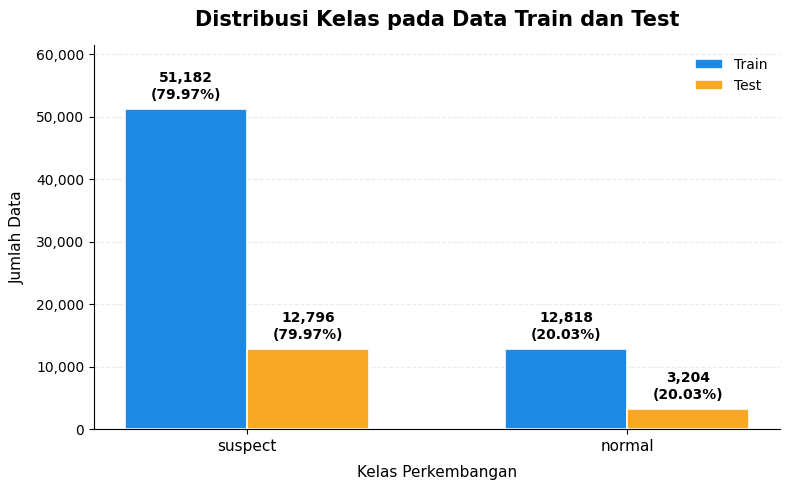

,Train (Jumlah),Train (%),Test (Jumlah),Test (%)
dev_status,,,,
suspect,51182,79.97,12796,79.97
normal,12818,20.03,3204,20.03


In [13]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np

# Menggunakan hasil split yang sudah tersedia
classes = ["suspect", "normal"]

train_counts = y_train.value_counts().reindex(classes, fill_value=0)
test_counts = y_test.value_counts().reindex(classes, fill_value=0)

train_percentages = train_counts / len(y_train) * 100
test_percentages = test_counts / len(y_test) * 100

# Posisi batang: TRAIN dan TEST bersebelahan dalam setiap kelas
x = np.arange(len(classes))
width = 0.32

fig, ax = plt.subplots(figsize=(8, 5))

bars_train = ax.bar(
    x - width / 2,
    train_counts.values,
    width,
    label="Train",
    color="#1E88E5",
    edgecolor="white",
    linewidth=1.2
)

bars_test = ax.bar(
    x + width / 2,
    test_counts.values,
    width,
    label="Test",
    color="#F9A825",
    edgecolor="white",
    linewidth=1.2
)

# Tampilkan jumlah di atas dan persentase di bawahnya
for bars, counts, percentages in [
    (bars_train, train_counts.values, train_percentages.values),
    (bars_test, test_counts.values, test_percentages.values)
]:
    for bar, count, percentage in zip(bars, counts, percentages):
        ax.annotate(
            f"{count:,}\n({percentage:.2f}%)",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            linespacing=1.3
        )

# Judul dan label
ax.set_title(
    "Distribusi Kelas pada Data Train dan Test",
    fontsize=15,
    fontweight="bold",
    pad=14
)
ax.set_xlabel("Kelas Perkembangan", fontsize=11, labelpad=8)
ax.set_ylabel("Jumlah Data", fontsize=11, labelpad=8)

ax.set_xticks(x)
ax.set_xticklabels(classes, fontsize=11)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}")
)

ax.legend(frameon=False, fontsize=10)

# Beri ruang di atas batang untuk label
max_count = max(train_counts.max(), test_counts.max())
ax.set_ylim(0, max_count * 1.20)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Tata letak dan simpan untuk Word
plt.tight_layout()
plt.savefig(
    "distribusi_train_test.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()

# Tampilkan ringkasan angka dalam bentuk teks
import pandas as pd

summary = pd.DataFrame({
    "Train (Jumlah)": train_counts,
    "Train (%)": train_percentages.round(2),
    "Test (Jumlah)": test_counts,
    "Test (%)": test_percentages.round(2)
})

display(summary)


## Min-Max Normalization

In [14]:
scaler = MinMaxScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_columns] = scaler.fit_transform(
    X_train[numeric_columns]
)

X_test_scaled[numeric_columns] = scaler.transform(
    X_test[numeric_columns]
)

print("✅ Min-Max Normalization selesai.")
print("Scaler hanya di-fit menggunakan TRAIN.")

✅ Min-Max Normalization selesai.
Scaler hanya di-fit menggunakan TRAIN.


## Cek hasil normalisasi

In [15]:
print("TRAIN setelah normalisasi:")
display(X_train_scaled[numeric_columns].describe())

print("\nTEST setelah normalisasi:")
display(X_test_scaled[numeric_columns].describe())

TRAIN setelah normalisasi:


,weight,height,age
count,64000.000000,64000.000000,64000.000000
mean,0.500684,0.498764,0.499447
std,0.305305,0.292633,0.342451
min,0.000000,0.000000,0.000000
25%,0.235294,0.242857,0.200000
50%,0.529412,0.500000,0.600000
75%,0.764706,0.757143,0.800000
max,1.000000,1.000000,1.000000



TEST setelah normalisasi:


,weight,height,age
count,16000.000000,16000.000000,16000.000000
mean,0.498099,0.496784,0.499750
std,0.304354,0.292392,0.342742
min,0.000000,0.000000,0.000000
25%,0.235294,0.242857,0.200000
50%,0.529412,0.500000,0.400000
75%,0.764706,0.742857,0.800000
max,1.000000,1.000000,1.000000


## Gabungkan kembali target

In [16]:
train_processed = X_train_scaled.copy()
train_processed["dev_status"] = y_train.values

test_processed = X_test_scaled.copy()
test_processed["dev_status"] = y_test.values

print("Train:", train_processed.shape)
print("Test :", test_processed.shape)

display(train_processed.head())

Train: (64000, 8)
Test : (16000, 8)


,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social,dev_status
24027,1.000000,0.685714,0.0,delayed,caution,normal,caution,suspect
15971,0.705882,0.857143,0.6,delayed,caution,caution,caution,suspect
23213,0.294118,0.500000,0.4,caution,delayed,normal,caution,suspect
2914,0.235294,0.400000,1.0,delayed,caution,advanced,caution,suspect
70369,0.294118,0.585714,0.8,advanced,normal,caution,advanced,normal


## Simpan dataset

In [17]:
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

train_processed.to_csv(
    PROCESSED_DIR / "train.csv",
    index=False
)

test_processed.to_csv(
    PROCESSED_DIR / "test.csv",
    index=False
)

print("✅ train.csv berhasil disimpan.")
print("✅ test.csv berhasil disimpan.")

✅ train.csv berhasil disimpan.
✅ test.csv berhasil disimpan.


# Simpan Scaler

In [18]:
SCALER_PATH = PROCESSED_DIR / "minmax_scaler.pkl"

joblib.dump(
    scaler,
    SCALER_PATH
)

print(f"✅ Scaler disimpan di: {SCALER_PATH}")

✅ Scaler disimpan di: ..\data\processed\minmax_scaler.pkl


## Final verification

In [19]:
print("=" * 50)
print("FINAL CHECKPOINT 3")
print("=" * 50)

print("Total dataset :", len(df))
print("Train         :", len(train_processed))
print("Test          :", len(test_processed))

print("\nProporsi:")
print("Train :", len(train_processed) / len(df) * 100, "%")
print("Test  :", len(test_processed) / len(df) * 100, "%")

print("\nKolom train:")
print(train_processed.columns.tolist())

print("\nKolom test:")
print(test_processed.columns.tolist())

print("\nFile berhasil disimpan:")
print(PROCESSED_DIR / "train.csv")
print(PROCESSED_DIR / "test.csv")
print(SCALER_PATH)

FINAL CHECKPOINT 3
Total dataset : 80000
Train         : 64000
Test          : 16000

Proporsi:
Train : 80.0 %
Test  : 20.0 %

Kolom train:
['weight', 'height', 'age', 'gross_motor', 'fine_motor_adaptive', 'language', 'personal_social', 'dev_status']

Kolom test:
['weight', 'height', 'age', 'gross_motor', 'fine_motor_adaptive', 'language', 'personal_social', 'dev_status']

File berhasil disimpan:
..\data\processed\train.csv
..\data\processed\test.csv
..\data\processed\minmax_scaler.pkl
